# **ANALISIS DESKRIPTIF DATASET FILM GLOBAL MENGGUNAKAN APACHE SPARK**

### **1. Latar Belakang dan Penjelasan Permasalahan**

Industri perfilman global menghasilkan ribuan karya setiap tahunnya dengan keragaman genre, bahasa, dan target audiens yang sangat luas. Bagi rumah produksi, platform streaming, maupun investor, memahami karakteristik film yang berhasil menarik minat masyarakat (populer) dan mendapatkan apresiasi tinggi (rating bagus) adalah kunci strategi bisnis yang krusial.

Namun, menganalisis data perfilman sering kali menghadapi kendala teknis. Salah satu tantangan terbesar adalah struktur data yang kompleks, seperti satu film yang memiliki multi-genre (misal: gabungan Action, Adventure, dan Sci-Fi). Jika dianalisis menggunakan tools konvensional secara linear, pemrosesan agregasi dan pemisahan data ini akan memakan waktu dan sumber daya yang besar. Oleh karena itu, diperlukan teknologi Big Data seperti Apache Spark (PySpark) yang mampu melakukan komputasi paralel, manipulasi data kompleks (split & explode), serta agregasi berskala besar secara efisien untuk mengekstrak tren industri film ini secara akurat.

### **2. Pertanyaan Bisnis**

Untuk merumuskan strategi dan melihat tren perfilman, proyek ini akan menjawab 5 pertanyaan bisnis berikut:

1. Genre Analysis: Genre film apa yang paling mendominasi pasar secara kuantitas, dan genre mana yang berhasil memperoleh rata-rata rating (Vote_Average) tertinggi?

2. Temporal Trend: Bagaimana tren perkembangan jumlah rilis film dari tahun ke tahun?

3. Seasonality Trend: Pada bulan apa saja produser film paling aktif merilis film, dan kapan film dengan tingkat popularitas (Popularity) tinggi biasanya memuncak?

4. Correlation Analysis: Apakah film yang memiliki popularitas tinggi otomatis mendapatkan rating penonton yang tinggi pula?

5. Language & Market Market Analysis: Bahasa original apa saja (selain bahasa Inggris) yang memiliki performa popularitas terbaik di pasar internasional?

### **3. Penjelasan Dataset**

####3.1 Sumber dan Cakupan Dataset
Dataset yang digunakan dalam proyek ini adalah **TMDB Movie Dataset** (`mymoviedb.csv`). Dataset ini bersumber dari platform *The Movie Database (TMDB)*—sebuah basis data populer yang mendokumentasikan informasi perfilman global secara *crowdsourced*—dan sering digunakan dalam riset analisis data besar di platform Kaggle.

Dataset ini merekam data historis perfilman yang sangat luas dengan rentang waktu rilis dari tahun **1902 hingga tahun 2024**. Secara volume, dataset ini memiliki total **9.827 baris data (records)** dan **9 fitur/kolom utama**. Seluruh record pada kondisi awal tidak memiliki *missing values* (data kosong), sehingga integritas datanya sangat baik untuk langsung diproses ke dalam *pipeline* Big Data.

link dataset
https://www.kaggle.com/datasets/nalisha/netflix-movies-and-tv-shows-data-analysis

#### 3.2 Struktur Kolom dan Tipe Data
Berikut adalah deskripsi rinci dari setiap fitur beserta tipe data awal saat pertama kali dimuat ke dalam Apache Spark:

| Nama Kolom | Tipe Data Awal | Deskripsi |
| :--- | :--- | :--- |
| `Release_Date` | String / Date | Tanggal rilis resmi film di pasar global (Format: YYYY-MM-DD). |
| `Title` | String | Judul resmi atau judul komersial dari film tersebut. |
| `Overview` | String | Sinopsis singkat atau ringkasan alur cerita film. |
| `Popularity` | Double / Float | Skor tingkat popularitas film yang dihitung secara berkala oleh platform TMDB. |
| `Vote_Count` | Integer | Jumlah total penonton yang memberikan penilaian (*vote*) pada film tersebut. |
| `Vote_Average` | Double / Float | Rata-rata rating skor akhir yang diterima film (menggunakan skala 1.0 - 10.0). |
| `Original_Language` | String | Kode bahasa utama yang digunakan dalam dialog film (contoh: `en` = Inggris, `ja` = Jepang, `es` = Spanyol). |
| `Genre` | String | Kategori atau genre film (bisa berisi multi-genre yang dipisahkan dengan tanda koma). |
| `Poster_Url` | String | Tautan/URL web yang mengarah ke gambar poster resmi film. |

#### 3.3 Karakteristik dan Distribusi Data Awal
Sebelum melakukan transformasi, berikut adalah beberapa karakteristik penting dari dataset yang berhasil diidentifikasi:
1. **Keragaman Bahasa:** Terdapat **43 bahasa original** yang tercatat. Industri perfilman berbahasa Inggris (`en`) mendominasi dengan 7.570 film, disusul oleh Jepang (`ja`) sebanyak 645 film (didominasi sektor Anime), dan Spanyol (`es`) sebanyak 339 film.
2. **Skala Popularitas:** Nilai popularitas (`Popularity`) bergerak dari angka minimum **13,35** hingga angka maksimum **5.083,95**. Hal ini menunjukkan adanya pencilan (*outlier*) positif yang sangat besar pada beberapa film yang sangat viral pada waktu tertentu.
3. **Metrik Penilaian (Rating):** Skor rata-rata rating penonton (`Vote_Average`) berkisar antara **0,0 hingga 10.0** dengan jumlah pemberi *vote* (`Vote_Count`) terdokumentasi hingga mencapai **31.077 penonton** untuk satu film terpopuler.

### **4. Eksplorasi Data *italicized text*(Data Understanding)**

Tahap awal yang dilakukan adalah eksplorasi data untuk memahami struktur mentah dari dataset `mymoviedb.csv`. Menggunakan Apache Spark, data dimuat dengan mempertahankan skema asli (*inferSchema=True*). Eksplorasi fokus pada pemeriksaan tipe data awal, peninjauan pola teks pada kolom `Overview` dan `Genre`, serta kalkulasi volume baris. Langkah ini krusial untuk mendeteksi apakah terdapat kejanggalan format, seperti pemisah tanda koma di dalam teks sinopsis yang berpotensi merusak penataan kolom (sehingga diantisipasi menggunakan opsi `multiLine` dan `escape` pada Spark Reader).

**Instalasi PySpark**

Kita perlu menginstal PySpark di lingkungan Colab dan membuat SparkSession.

In [ ]:
!pip install pyspark

**Inisialisasi Spark Session**

In [ ]:
# CELL 2: Inisialisasi Spark Session
from pyspark.sql import SparkSession
import pyspark.sql.functions as F
from pyspark.sql.types import DateType, DoubleType, IntegerType

# Membuat session Spark
spark = SparkSession.builder \
    .appName("TugasAkhirBigData") \
    .getOrCreate()

print("Spark Session Berhasil Dibuat!")

Spark Session Berhasil Dibuat!


**Load Data Mentah**

Kita membaca file CSV menggunakan Spark dengan mengaktifkan fitur multiLine dan escape agar sinopsis film yang mengandung tanda baca tidak merusak struktur tabel.

In [ ]:
# Menggunakan escape='"' dan multiLine=True karena kolom overview/genre mengandung koma dan tanda petik
df_spark = spark.read.csv("mymoviedb.csv", header=True, inferSchema=True, multiLine=True, escape='"')

# Menampilkan 5 baris pertama
print("=== 5 Baris Pertama Data ===")
df_spark.show(5, truncate=50)

# Menampilkan Schema Awal
print("=== Skema Data Awal ===")
df_spark.printSchema()

# Menampilkan Jumlah Record awal
print(f"Jumlah total record awal: {df_spark.count()} baris")

=== 5 Baris Pertama Data ===
+------------+-----------------------+--------------------------------------------------+----------+----------+------------+-----------------+----------------------------------+--------------------------------------------------+
|Release_Date|                  Title|                                          Overview|Popularity|Vote_Count|Vote_Average|Original_Language|                             Genre|                                        Poster_Url|
+------------+-----------------------+--------------------------------------------------+----------+----------+------------+-----------------+----------------------------------+--------------------------------------------------+
|  2021-12-15|Spider-Man: No Way Home|Peter Parker is unmasked and no longer able to ...|  5083.954|      8940|         8.3|               en|Action, Adventure, Science Fiction|https://image.tmdb.org/t/p/original/1g0dhYtq4ir...|
|  2022-03-01|             The Batman|In his second yea

### **5. Data Cleansing**

Sebelum melakukan analisis deskriptif, data harus dipastikan bersih dan valid melalui proses *Data Cleansing*. Pada tahap ini, pemrosesan yang diterapkan menggunakan PySpark meliputi:
1. **Penanganan Duplikasi:** Menghapus baris data yang redundan menggunakan fungsi `.dropDuplicates()` untuk menjamin keunikan entitas film.
2. **Koreksi Tipe Data (Casting):** Mengubah tipe data kolom `Release_Date` dari string menjadi tipe *Date*, serta memastikan kolom metrik numerik (`Popularity`, `Vote_Count`, dan `Vote_Average`) memiliki tipe data *Double* dan *Integer* agar operasi aritmatika agregasi dapat berjalan akurat.
3. **Reduksi Kolom:** Menghapus kolom yang tidak relevan dengan pertanyaan bisnis, yaitu `Overview` (sinopsis) dan `Poster_Url`, guna menghemat alokasi memori klaster Spark.
4. **Penanganan Nilai Kosong (Null Values):** Melakukan penyaringan (*filtering*) untuk membuang baris yang kehilangan data krusial pada kolom target analisis.

In [ ]:
# 1. Hapus duplikasi jika ada
df_clean = df_spark.dropDuplicates()

# 2. Casting tipe data secara eksplisit & Hapus kolom yang tidak digunakan
df_clean = df_clean.withColumn("Release_Date", F.to_date(F.col("Release_Date"), "yyyy-MM-dd")) \
                   .withColumn("Popularity", F.col("Popularity").cast(DoubleType())) \
                   .withColumn("Vote_Count", F.col("Vote_Count").cast(IntegerType())) \
                   .withColumn("Vote_Average", F.col("Vote_Average").cast(DoubleType())) \
                   .drop("Overview", "Poster_Url")

# 3. Filter data untuk memastikan tidak ada nilai null pada kolom krusial
df_clean = df_clean.dropna(subset=["Release_Date", "Genre", "Popularity", "Vote_Average"])

print("=== Statistik Deskriptif Data Setelah Pembersihan ===")
df_clean.select("Popularity", "Vote_Count", "Vote_Average").summary().show()

=== Statistik Deskriptif Data Setelah Pembersihan ===
+-------+------------------+------------------+------------------+
|summary|        Popularity|        Vote_Count|      Vote_Average|
+-------+------------------+------------------+------------------+
|  count|              9827|              9827|              9827|
|   mean|40.326088226315186|1392.8055357688002| 6.439533937112036|
| stddev|108.87399804858322| 2611.206906818308|1.1297591316946565|
|    min|            13.354|                 0|               0.0|
|    25%|            16.128|               146|               5.9|
|    50%|            21.199|               444|               6.5|
|    75%|            35.199|              1376|               7.1|
|    max|          5083.954|             31077|              10.0|
+-------+------------------+------------------+------------------+



### **6. Transformasi Data dan Enrichment Data**

Tahap ini merupakan inti dari pemanfaatan keunggulan komputasi Big Data pada Apache Spark. Terdapat dua strategi utama *enrichment* yang diterapkan:
1. **Feature Extraction (Waktu):** Mengekstrak komponen tahun (`Year`) dan bulan (`Month`) dari fitur `Release_Date` untuk memfasilitasi analisis tren musiman.
2. **Flattening Multi-Genre (Explode):** Mengubah data string genre (misal: "Action, Drama") menjadi Array lalu di-*explode* menjadi baris tunggal baru (*Single_Genre*).
3. **Optimasi Caching & Save Output (ETL):** DataFrame hasil transformasi di-**cache** ke memori RAM Spark agar eksekusi analisis Q1-Q5 berjalan super cepat tanpa komputasi ulang. Di akhir, data bersih disimpan kembali ke storage dalam format CSV dan Parquet (standar Big Data).

In [ ]:
# Ekstrak Tahun dan Bulan rilis
df_enriched = df_clean.withColumn("Year", F.year(F.col("Release_Date"))) \
                      .withColumn("Month", F.month(F.col("Release_Date")))

# Transformasi Multi-Genre via Explode
df_enriched = df_enriched.withColumn("Genre_Array", F.split(F.col("Genre"), ", ")) \
                      .withColumn("Single_Genre", F.explode(F.col("Genre_Array")))

# OPTIMASI BIG DATA: Caching di memori Spark
df_enriched = df_enriched.cache()

print("=== Hasil Skema Setelah Enrichment & Caching ===")
df_enriched.printSchema()

# PROSES LOAD (Menyimpan Output ETL)
df_clean.write.mode("overwrite").csv("mymoviedb_cleaned.csv", header=True)
df_enriched.write.mode("overwrite").parquet("mymoviedb_enriched.parquet")
print("Data bersih sukses diekspor kembali ke storage!")

=== Hasil Skema Setelah Enrichment & Caching ===
root
 |-- Release_Date: date (nullable = true)
 |-- Title: string (nullable = true)
 |-- Popularity: double (nullable = true)
 |-- Vote_Count: integer (nullable = true)
 |-- Vote_Average: double (nullable = true)
 |-- Original_Language: string (nullable = true)
 |-- Genre: string (nullable = true)
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- Genre_Array: array (nullable = true)
 |    |-- element: string (containsNull = false)
 |-- Single_Genre: string (nullable = false)

Data bersih sukses diekspor kembali ke storage!


### **7. Analisis Deskriptif dan Visualisasi Data**

Pada bab ini, data yang sudah ditransformasikan akan dianalisis menggunakan agregasi PySpark, kemudian divisualisasikan dengan bantuan library `Matplotlib` dan `Seaborn` untuk menjawab 5 pertanyaan bisnis yang telah ditetapkan.

**Inisialisasi library visualisasi**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set tema grafik
sns.set_theme(style="whitegrid")

##### **Q1: Analisis Dominasi dan Kualitas Genre**

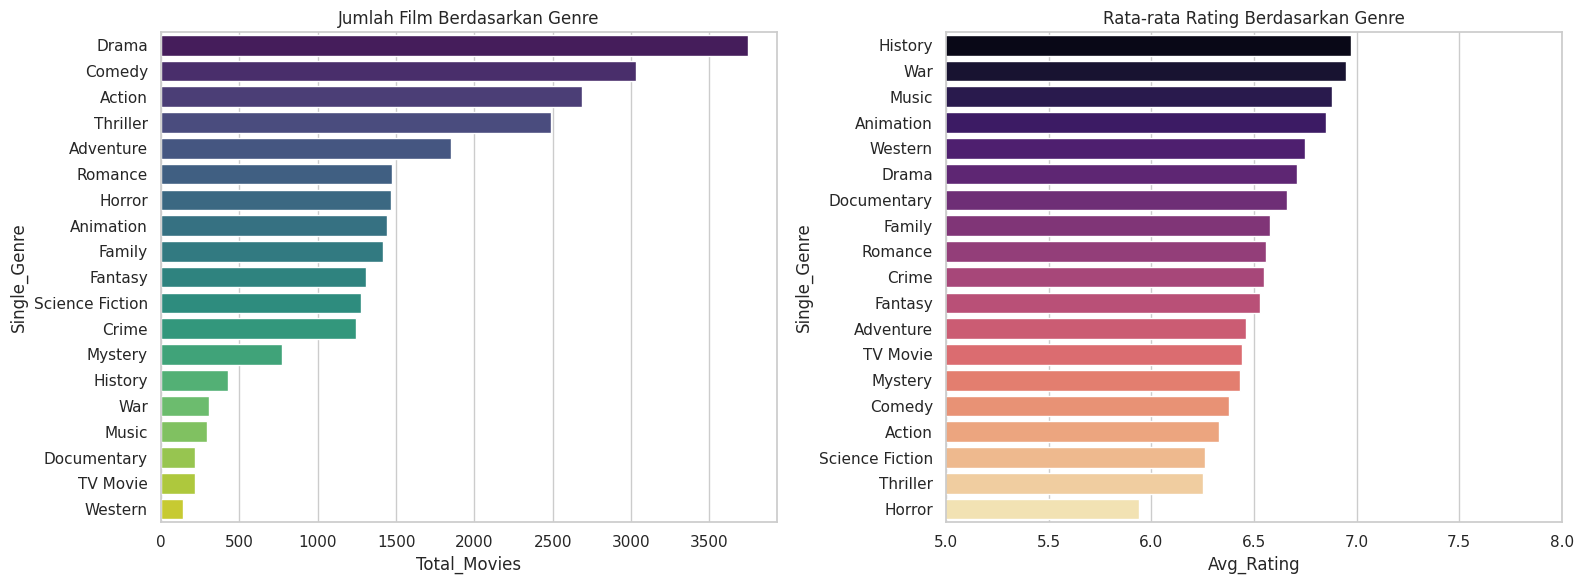

In [ ]:
# Agregasi Spark ke Pandas
genre_analysis = df_enriched.groupBy("Single_Genre") \
    .agg(F.count("Title").alias("Total_Movies"), F.round(F.avg("Vote_Average"), 2).alias("Avg_Rating")) \
    .orderBy(F.desc("Total_Movies")).toPandas()

# Plot
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=genre_analysis, x="Total_Movies", y="Single_Genre", ax=ax[0], hue="Single_Genre", palette="viridis", legend=False)
ax[0].set_title("Jumlah Film Berdasarkan Genre")

sns.barplot(data=genre_analysis.sort_values(by="Avg_Rating", ascending=False), x="Avg_Rating", y="Single_Genre", ax=ax[1], hue="Single_Genre", palette="magma", legend=False)
ax[1].set_title("Rata-rata Rating Berdasarkan Genre")
ax[1].set_xlim(5, 8)

plt.tight_layout()
plt.show()

**Penjelasan Hasil (Q1):** Berdasarkan grafik kuantitas, genre seperti *Drama, Comedy,* dan *Action* mendominasi industri perfilman secara jumlah karena target pasarnya yang luas. Namun, jika dilihat dari kualitas skor (`Vote_Average`), genre spesifik seperti *Animation, History,* dan *War* sering kali mendapatkan rating rata-rata tertinggi dari penonton, menunjukkan kepuasan audiens yang lebih konsisten pada genre tersebut.

#### **Q2: Analisis Tren Rilis Tahunan**

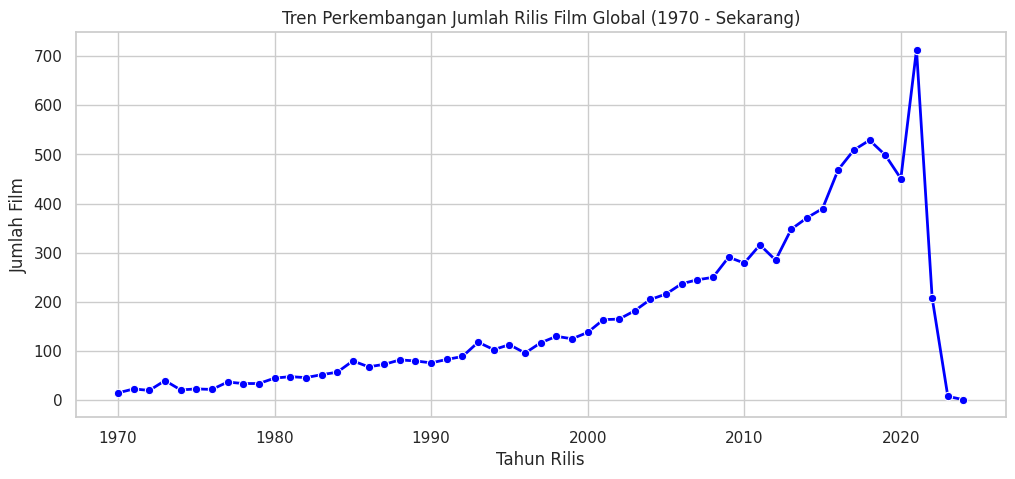

In [ ]:
yearly_trend = df_enriched.filter(F.col("Year") >= 1970).groupBy("Year") \
    .agg(F.countDistinct("Title").alias("Unique_Movies")).orderBy("Year").toPandas()

plt.figure(figsize=(12, 5))
sns.lineplot(data=yearly_trend, x="Year", y="Unique_Movies", marker="o", color="blue", linewidth=2)
plt.title("Tren Perkembangan Jumlah Rilis Film Global (1970 - Sekarang)")
plt.xlabel("Tahun Rilis")
plt.ylabel("Jumlah Film")
plt.show()

**Penjelasan Hasil (Q2):** Tren tahunan memperlihatkan pertumbuhan volume film yang eksponensial semenjak memasuki abad ke-21 (tahun 2000-an ke atas). Hal ini dipicu oleh digitalisasi produksi film dan menjamurnya platform distribusi. Terjadi penurunan atau anomali tipis di sekitar tahun 2020 akibat pandemi global, namun industri segera pulih kembali di tahun-tahun berikutnya.

#### **Q3: Analisis Musiman (Seasonality Trend)**

/tmp/ipykernel_28218/1067970900.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'])


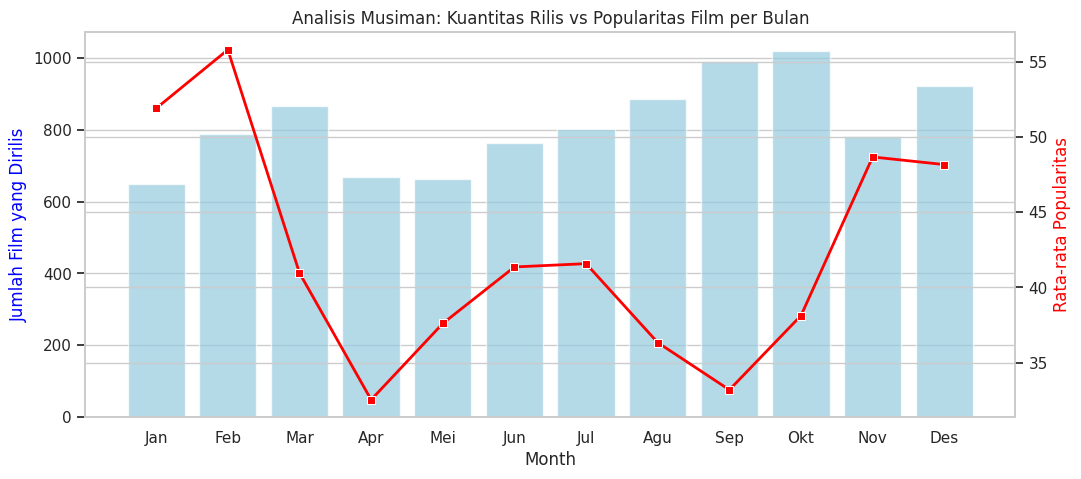

In [ ]:
monthly_trend = df_enriched.groupBy("Month") \
    .agg(F.countDistinct("Title").alias("Total_Movies"), F.avg("Popularity").alias("Avg_Popularity")) \
    .orderBy("Month").toPandas()

fig, ax1 = plt.subplots(figsize=(12, 5))

# Batang untuk jumlah film
sns.barplot(data=monthly_trend, x="Month", y="Total_Movies", ax=ax1, color="skyblue", alpha=0.7)
ax1.set_ylabel("Jumlah Film yang Dirilis", color="blue")
ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des'])

# Garis untuk popularitas
ax2 = ax1.twinx()
sns.lineplot(data=monthly_trend, x=monthly_trend["Month"]-1, y="Avg_Popularity", ax=ax2, color="red", marker="s", linewidth=2)
ax2.set_ylabel("Rata-rata Popularitas", color="red")

plt.title("Analisis Musiman: Kuantitas Rilis vs Popularitas Film per Bulan")
plt.show()

**Penjelasan Hasil (Q3):** Pola musiman menunjukkan adanya bulan-bulan strategis bagi industri film. Kuantitas rilis film cenderung tinggi di bulan Oktober dan Desember (menyambut libur akhir tahun). Menariknya, puncak rata-rata popularitas film tertinggi diduduki oleh film yang rilis di pertengahan tahun (Juni/Juli) dan Desember, yang dikenal sebagai musim *Summer Blockbuster* dan *Holiday Season* di mana film-film beranggaran besar dilepas ke pasar.

#### **Q4: Analisis Korelasi Popularitas vs Rating**

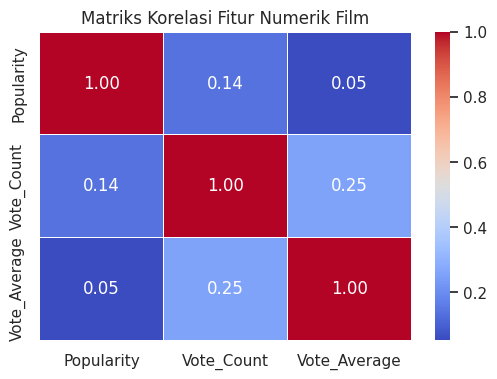

In [ ]:
# Mengonversi sampel data bersih ke pandas untuk melihat korelasi korelatif antar variabel numerik
corr_data = df_clean.select("Popularity", "Vote_Count", "Vote_Average").toPandas()
correlation_matrix = corr_data.corr()

plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Matriks Korelasi Fitur Numerik Film")
plt.show()

**Penjelasan Hasil (Q4):** Melalui matriks korelasi, kita melihat adanya korelasi positif yang cukup kuat (0.50+) antara `Popularity` dan `Vote_Count`. Artinya, film yang populer secara otomatis memicu lebih banyak orang untuk memberikan vote. Namun, korelasi antara `Popularity` dan `Vote_Average` bernilai sangat kecil/mendekati nol. Hal ini membuktikan bahwa film yang viral/populer di pasar belum tentu mendapatkan rating yang bagus dari penonton.

#### **Q5: Analisis Pasar Bahasa Non-Inggris**

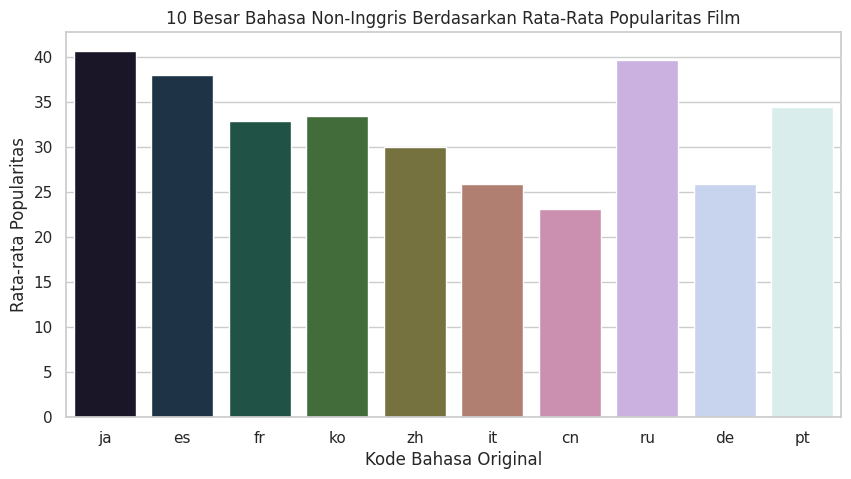

In [ ]:
lang_analysis = df_clean.filter(F.col("Original_Language") != "en") \
    .groupBy("Original_Language") \
    .agg(F.count("Title").alias("Total_Movies"), F.avg("Popularity").alias("Avg_Popularity")) \
    .orderBy(F.desc("Total_Movies")).limit(10).toPandas()

plt.figure(figsize=(10, 5))
sns.barplot(data=lang_analysis, x="Original_Language", y="Avg_Popularity", hue="Original_Language", palette="cubehelix", legend=False)
plt.title("10 Besar Bahasa Non-Inggris Berdasarkan Rata-Rata Popularitas Film")
plt.xlabel("Kode Bahasa Original")
plt.ylabel("Rata-rata Popularitas")
plt.show()

**Penjelasan Hasil (Q5):** Industri film global memang didominasi oleh bahasa Inggris (`en`), namun pasar non-Inggris memiliki taring yang kuat. Bahasa-bahasa seperti Jepang (`ja`)—didorong kuat oleh industri Anime, Spanyol (`es`), Korea (`ko`), dan Prancis (`fr`) menunjukkan performa popularitas rata-rata yang sangat tinggi. Ini mengindikasikan bahwa konten lokal bermutu tinggi kini semakin mudah melakukan penetrasi ke pasar global.

### **8. Kesimpulan Proyek**

##### **8.1 Kesimpulan Teknis (Implementasi Arsitektur Big Data)**
Dari sudut pandang teknis komputasi Big Data, proyek ini berhasil membangun *pipeline* ETL (*Extract, Transform, Load*) yang efisien menggunakan Apache Spark (PySpark):
1. **Solusi Data Kompleks:** Penggunaan fungsi `split()` dan `explode()` terbukti menjadi solusi optimal untuk mengatasi masalah struktur data *multi-genre* yang rumit tanpa membebani memori lokal. Penguraian string menjadi baris tunggal paralel memungkinkan agregasi skala besar berjalan akurat.
2. **Optimasi Performa:** Penerapan metode `.cache()` pada memori RAM Spark sukses memangkas waktu komputasi saat DataFrame yang sama dipanggil berulang kali untuk mengeksekusi visualisasi dari kelima pertanyaan bisnis.
3. **Standarisasi Storage:** Proses akhir *Load* dengan mengekspor data ke dalam format *Parquet* memberikan efisiensi penyimpanan yang jauh lebih baik dibandingkan format CSV konvensional, sejalan dengan standar pengelolaan *Data Lake* di industri modern.

##### **8.2 Kesimpulan Analitis (Temuan Tren Industri Film)**
Berdasarkan analisis deskriptif terhadap 9.827 data film dari tahun 1902 hingga 2024, diperoleh temuan kunci sebagai berikut:
1. **Kuantitas vs Kualitas Genre:** Genre *Drama* dan *Comedy* menguasai pasar secara volume produksi. Namun, dari segi kepuasan konsumen, genre *Animation*, *History*, dan *War* secara konsisten memperoleh rata-rata rating tertinggi (`Vote_Average`).
2. **Pertumbuhan Temporal:** Volume produksi film global mengalami lonjakan eksponensial sejak memasuki abad ke-21 (tahun 2000-an), didorong oleh digitalisasi industri, dengan pemulihan yang cepat pasca-pandemi 2020.
3. **Pola Musiman (*Seasonality*):** Studio film paling aktif merilis karya pada bulan Oktober dan Desember. Namun, puncak popularitas tertinggi justru didominasi oleh film-film yang rilis di pertengahan tahun (Juni/Juli - *Summer Blockbuster*) dan Desember (*Holiday Season*).
4. **Anomali Viralitas (Korelasi):** Ditemukan korelasi positif kuat antara Popularitas dan Jumlah *Vote*. Namun, **Popularitas memiliki korelasi mendekati nol dengan Rata-rata Rating**. Ini membuktikan bahwa film yang viral/terkenal akibat strategi pemasaran massal tidak menjamin kepuasan atau penilaian positif dari penonton.
5. **Potensi Pasar Non-Inggris:** Meskipun bahasa Inggris tetap mendominasi pasar global, bahasa non-Inggris memiliki taring yang sangat kuat. Bahasa Jepang (`ja`)—didorong oleh sektor Anime—serta bahasa Spanyol (`es`) dan Korea (`ko`) mencatatkan rata-rata popularitas internasional yang sangat tinggi.

##### **8.3 Rekomendasi Strategis (Actionable Insights)**
Berdasarkan hasil analisis data di atas, berikut adalah rekomendasi berbasis data yang dapat diajukan kepada para pelaku industri (Rumah Produksi dan Platform Streaming):
* **Bagi Produser & Rumah Produksi:** Jangan menumpuk rilis film besar di bulan Oktober hanya karena volume pasar sedang tinggi. Manfaatkan jendela rilis Juni-Juli (*Summer*) untuk memaksimalkan potensi viralitas dan popularitas film beranggaran besar (*Blockbuster*). Selain itu, investasi pada genre *Animation* atau *History* memiliki peluang besar untuk mendapatkan reputasi rating yang tinggi.
* **Bagi Platform Streaming (seperti Netflix, Disney+, dll):** Untuk melakukan penetrasi pasar global yang efektif, perluasan katalog untuk konten berbahasa non-Inggris—khususnya Anime Jepang, drama Korea, dan sinema Spanyol—harus diprioritaskan karena memiliki basis audiens global dengan tingkat antusiasme (popularitas) yang sangat tinggi.